# EDа: аварии на нефтепроводах США

Датасет Oil Pipeline Accidents: отчеты операторов трубопроводов в PHMSA (американский регулятор) за 2010–2017 годы. Одна строка — одна авария. Скачивается скриптом `data_loader.py` из ДЗ №2.

Цель — понять, насколько данным можно доверять и что с ними придется делать в ETL.

План:
1. Загрузка
2. Структура и типы
3. Пропуски, дубликаты, полнота
4. Проверка значений и бизнес-правил
5. Выбросы
6. Корреляции
7. Метрики качества
8. Выводы

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")  # чтобы предупреждения библиотек не засоряли вывод

# data_loader.py лежит в корне репозитория, на уровень выше
ROOT = Path("..").resolve() if Path("../data_loader.py").exists() else Path(".").resolve()
sys.path.append(str(ROOT))
from data_loader import download_dataset, convert_column_types

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Загрузка

Читаю CSV без приведения типов, чтобы увидеть данные такими, какие они приходят из источника.

In [2]:
data_file = ROOT / "data" / "Oil_Pipeline_Accidents.csv"
if not data_file.exists():
    download_dataset()

raw = pd.read_csv(data_file, low_memory=False)
print(raw.shape)
raw.head(3)

(2795, 48)


,Report Number,Supplemental Number,Accident Year,Accident Date/Time,Operator ID,Operator Name,Pipeline/Facility Name,Pipeline Location,Pipeline Type,Liquid Type,Liquid Subtype,Liquid Name,Accident City,Accident County,Accident State,Accident Latitude,Accident Longitude,Cause Category,Cause Subcategory,Unintentional Release (Barrels),Intentional Release (Barrels),Liquid Recovery (Barrels),Net Loss (Barrels),Liquid Ignition,Liquid Explosion,Pipeline Shutdown,Shutdown Date/Time,Restart Date/Time,Public Evacuations,Operator Employee Injuries,Operator Contractor Injuries,Emergency Responder Injuries,Other Injuries,Public Injuries,All Injuries,Operator Employee Fatalities,Operator Contractor Fatalities,Emergency Responder Fatalities,Other Fatalities,Public Fatalities,All Fatalities,Property Damage Costs,Lost Commodity Costs,Public/Private Property Damage Costs,Emergency Response Costs,Environmental Remediation Costs,Other Costs,All Costs
0,20100016,17305,2010,1/1/2010 7:15 AM,32109,ONEOK NGL PIPELINE LP,KINDER MORGAN JCT,ONSHORE,ABOVEGROUND,"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",LPG (LIQUEFIED PETROLEUM GAS) / NGL (NATURAL G...,NaN,MCPHERSON,MCPHERSON,KS,38.67070,-97.78123,INCORRECT OPERATION,PIPELINE/EQUIPMENT OVERPRESSURED,21.00,0.1,0.00,21.0,NO,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,110.0,1517.0,0.0,0.0,0.0,0.0,1627
1,20100254,17331,2010,1/4/2010 8:30 AM,15786,PORTLAND PIPELINE CORP,24-INCH MAIN LINE,ONSHORE,ABOVEGROUND,CRUDE OIL,NaN,NaN,RAYMOND,CUMBERLAND,ME,43.94028,-70.49336,MATERIAL/WELD/EQUIP FAILURE,PUMP OR PUMP-RELATED EQUIPMENT,0.12,0.0,0.12,0.0,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4000.0,8.0,0.0,0.0,0.0,0.0,4008
2,20100038,17747,2010,1/5/2010 10:30 AM,20160,"PETROLOGISTICS OLEFINS, LLC",NaN,ONSHORE,ABOVEGROUND,"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",OTHER HVL,ETHANE,SULPHER,CALCASIEU,LA,30.18240,-93.35240,MATERIAL/WELD/EQUIP FAILURE,DEFECTIVE OR LOOSE TUBING/FITTING,2.00,0.0,0.00,2.0,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,200.0,0.0,0.0,0.0,0.0,200


2795 строк и 48 столбцов. Столбцы можно разбить на группы: идентификаторы отчета, время аварии и остановки трубопровода, оператор, место, тип продукта, причина, объемы утечки в баррелях, последствия (возгорание, взрыв, эвакуация), пострадавшие и затраты. Таблица денормализованная: оператор и место хранятся прямо в строке аварии.

## 2. Структура и типы

In [3]:
raw.dtypes.value_counts()

float64    25
object     18
int64       5
Name: count, dtype: int64

In [4]:
raw.select_dtypes("object").columns.tolist()

['Accident Date/Time',
 'Operator Name',
 'Pipeline/Facility Name',
 'Pipeline Location',
 'Pipeline Type',
 'Liquid Type',
 'Liquid Subtype',
 'Liquid Name',
 'Accident City',
 'Accident County',
 'Accident State',
 'Cause Category',
 'Cause Subcategory',
 'Liquid Ignition',
 'Liquid Explosion',
 'Pipeline Shutdown',
 'Shutdown Date/Time',
 'Restart Date/Time']

Среди строковых столбцов есть три даты и три флага YES/NO. Их надо будет переводить в `datetime` и `bool`.

Еще проверю float-столбцы: в некоторых из них на самом деле только целые числа.

In [5]:
int_like = [c for c in raw.select_dtypes("float").columns if (raw[c].dropna() % 1 == 0).all()]
int_like

['Public Evacuations',
 'Operator Employee Injuries',
 'Operator Contractor Injuries',
 'Emergency Responder Injuries',
 'Other Injuries',
 'Public Injuries',
 'All Injuries',
 'Operator Employee Fatalities',
 'Operator Contractor Fatalities',
 'Emergency Responder Fatalities',
 'Other Fatalities',
 'Public Fatalities',
 'All Fatalities',
 'Property Damage Costs',
 'Lost Commodity Costs',
 'Public/Private Property Damage Costs',
 'Emergency Response Costs',
 'Environmental Remediation Costs',
 'Other Costs']

Счетчики людей (пострадавшие, погибшие, эвакуированные) хранятся как float только потому, что в них есть пропуски. Для них подойдет `Int64`. Затраты тоже целые, но для денег float не страшен.

Посмотрю на форматы дат:

In [6]:
date_cols = ["Accident Date/Time", "Shutdown Date/Time", "Restart Date/Time"]
raw[date_cols].dropna().head(3)

,Accident Date/Time,Shutdown Date/Time,Restart Date/Time
5,1/8/2010 11:38 PM,1/8/2010 23:41,1/13/2010 9:17
10,1/11/2010 2:30 PM,1/11/2010 14:45,1/15/2010 15:00
11,1/11/2010 2:47 PM,1/11/2010 14:55,1/11/2010 22:08


Форматы разные: время аварии записано с AM/PM, а время остановки и перезапуска — в 24-часовом формате. Значит, парсить каждый столбец нужно со своим форматом. Проверю, что все парсится:

In [7]:
formats = {
    "Accident Date/Time": "%m/%d/%Y %I:%M %p",
    "Shutdown Date/Time": "%m/%d/%Y %H:%M",
    "Restart Date/Time": "%m/%d/%Y %H:%M",
}
for col, fmt in formats.items():
    parsed = pd.to_datetime(raw[col], format=fmt, errors="coerce")
    print(col, "- не распарсилось:", (parsed.isna() & raw[col].notna()).sum())

flag_cols = ["Liquid Ignition", "Liquid Explosion", "Pipeline Shutdown"]
print("Значения флагов:", sorted(raw[flag_cols].stack().unique()))
print("Report Number из 8 цифр:", raw["Report Number"].astype(str).str.fullmatch(r"\d{8}").all())
print("Коды штатов из 2 букв:", raw["Accident State"].dropna().str.fullmatch(r"[A-Z]{2}").all())

Accident Date/Time - не распарсилось: 0
Shutdown Date/Time - не распарсилось: 0
Restart Date/Time - не распарсилось: 0
Значения флагов: ['NO', 'YES']
Report Number из 8 цифр: True
Коды штатов из 2 букв: True


Форматы соблюдаются везде. Теперь применю `convert_column_types` из ДЗ №3 и проверю, не потерялись ли значения.

In [8]:
df = convert_column_types(raw)

print("Pipeline Shutdown до:   ", raw["Pipeline Shutdown"].value_counts(dropna=False).to_dict())
print("Pipeline Shutdown после:", df["Pipeline Shutdown"].value_counts(dropna=False).to_dict())

Pipeline Shutdown до:    {'YES': 1395, 'NO': 1188, nan: 212}
Pipeline Shutdown после: {False: 1400, True: 1395}


Нашлась ошибка в моем же ДЗ №3: `eq("YES")` превращает пропуск в `False`. В итоге 212 аварий, по которым неизвестно, останавливали ли трубопровод, стали «не останавливали». Исправляю на nullable `boolean` и сразу считаю длительность простоя.

In [9]:
for col in flag_cols:
    df[col] = raw[col].map({"YES": True, "NO": False}).astype("boolean")

df["Downtime Hours"] = (df["Restart Date/Time"] - df["Shutdown Date/Time"]).dt.total_seconds() / 3600
df["Pipeline Shutdown"].value_counts(dropna=False)

Pipeline Shutdown
True     1395
False    1188
<NA>      212
Name: count, dtype: Int64

## 3. Пропуски, дубликаты, полнота

In [10]:
na = raw.isna().mean().sort_values(ascending=False)
na = na[na > 0]
print("Столбцов с пропусками:", len(na))
na.round(3)

Столбцов с пропусками: 30


All Fatalities                          0.997
Operator Employee Fatalities            0.997
Operator Contractor Fatalities          0.997
Emergency Responder Fatalities          0.997
Other Fatalities                        0.997
Public Fatalities                       0.997
Emergency Responder Injuries            0.996
Operator Employee Injuries              0.996
Other Injuries                          0.996
Public Injuries                         0.996
All Injuries                            0.996
Operator Contractor Injuries            0.996
Liquid Name                             0.921
Intentional Release (Barrels)           0.567
Restart Date/Time                       0.520
Liquid Subtype                          0.517
Shutdown Date/Time                      0.503
Public Evacuations                      0.164
Accident City                           0.113
Pipeline Shutdown                       0.076
Pipeline/Facility Name                  0.043
Accident County                   

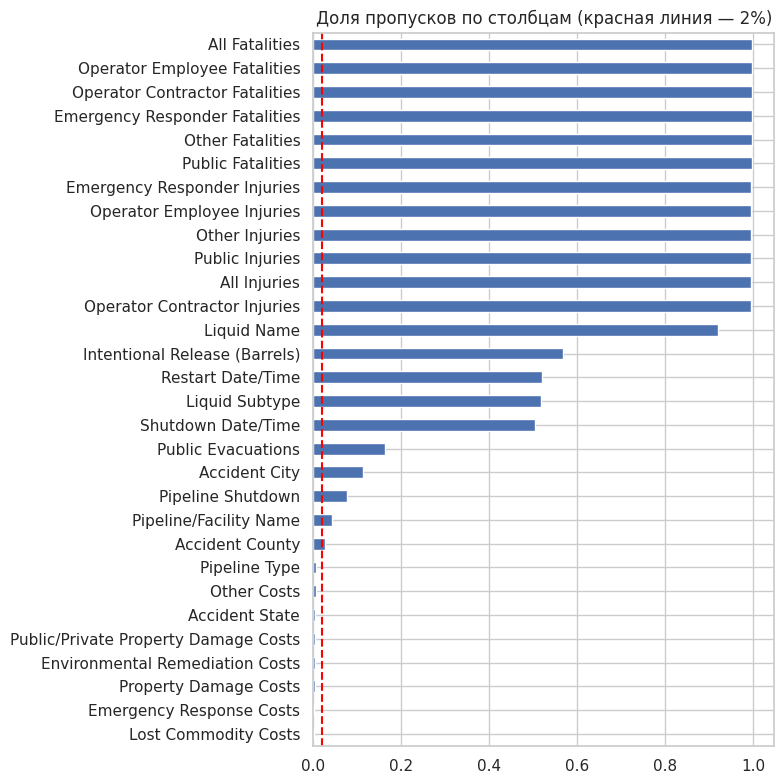

In [11]:
na.sort_values().plot.barh(figsize=(8, 8))
plt.axvline(0.02, color="red", linestyle="--")
plt.title("Доля пропусков по столбцам (красная линия — 2%)")
plt.tight_layout()
plt.show()

Пропуски есть в 30 столбцах. Но у них разная природа, и обрабатывать их надо по-разному.

**Пропуски, где поле неприменимо.** `Pipeline Type` пуст только у морских трубопроводов, `Liquid Subtype` — у нефти и CO₂ (у них нет подтипов), а `Liquid Name` заполняется только для подтипа OTHER.

In [12]:
print(raw.loc[raw["Pipeline Type"].isna(), "Pipeline Location"].value_counts())
pd.crosstab(raw["Liquid Type"], raw["Liquid Subtype"].isna())

Pipeline Location
OFFSHORE    18
Name: count, dtype: int64


Liquid Subtype,False,True
Liquid Type,,
BIOFUEL / ALTERNATIVE FUEL(INCLUDING ETHANOL BLENDS),2,0
CO2 (CARBON DIOXIDE),0,38
CRUDE OIL,0,1398
"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",414,4
"REFINED AND/OR PETROLEUM PRODUCT (NON-HVL), LIQUID",933,6


In [13]:
pd.crosstab(raw["Liquid Subtype"].fillna("нет подтипа"), raw["Liquid Name"].notna())

Liquid Name,False,True
Liquid Subtype,,
ANHYDROUS AMMONIA,55,0
BIODIESEL,2,0
"DIESEL, FUEL OIL, KEROSENE, JET FUEL",408,0
GASOLINE (NON-ETHANOL),376,0
LPG (LIQUEFIED PETROLEUM GAS) / NGL (NATURAL GAS LIQUID),188,0
MIXTURE OF REFINED PRODUCTS (TRANSMIX OR OTHER MIXTURE),98,0
OTHER,0,51
OTHER HVL,0,171
нет подтипа,1446,0


**Пропуск означает ноль.** Поля о пострадавших заполнены всего у 14 аварий:

In [14]:
victim_cols = [c for c in raw.columns if "Injuries" in c or "Fatalities" in c]
filled = raw[victim_cols].notna().any(axis=1)
print("Строк с заполненными полями о пострадавших:", filled.sum())
raw.loc[filled, ["All Injuries", "All Fatalities"]].describe().loc[["count", "min", "max"]]

Строк с заполненными полями о пострадавших: 14


,All Injuries,All Fatalities
count,12.0,8.0
min,1.0,1.0
max,4.0,2.0


Минимум там 1 человек, то есть блок заполняют только тогда, когда пострадавшие есть. Значит, NaN здесь можно заменить на 0.

**Пропуски, которые меняются по годам.** Посмотрю долю пропусков в нескольких столбцах по годам:

In [15]:
cols = ["Intentional Release (Barrels)", "Public Evacuations", "Pipeline Shutdown", "Accident City"]
by_year = raw[cols].isna().groupby(raw["Accident Year"]).mean()
by_year.round(2)

,Intentional Release (Barrels),Public Evacuations,Pipeline Shutdown,Accident City
Accident Year,,,,
2010,0.19,0.38,0.13,0.06
2011,0.08,0.31,0.17,0.07
2012,0.14,0.22,0.09,0.03
2013,0.77,0.20,0.11,0.04
2014,0.89,0.13,0.06,0.09
2015,0.85,0.00,0.00,0.23
2016,0.80,0.00,0.00,0.22
2017,1.00,0.00,0.00,0.00


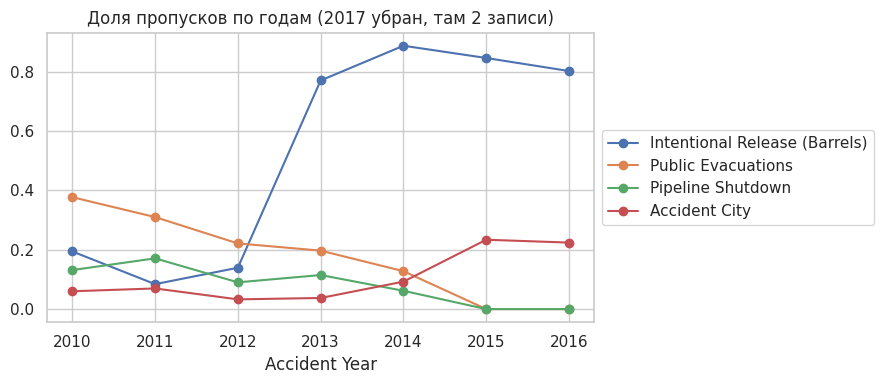

In [16]:
by_year.drop(index=2017).plot(marker="o", figsize=(9, 4))
plt.title("Доля пропусков по годам (2017 убран, там 2 записи)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Похоже, форма отчета менялась:
- `Public Evacuations` и `Pipeline Shutdown` с 2015 года заполнены всегда, а раньше пропусков было до 38%;
- `Intentional Release` наоборот: с 2013 года пустует в 77–89% записей;
- `Accident City` в 2015–2016 годах пропущен в 22–23% записей против 3–9% раньше.

Поэтому сравнивать эти поля между годами напрямую нельзя.

**Дубликаты.**

In [17]:
print("Report Number уникален:", raw["Report Number"].is_unique)
print("Полных дубликатов:", raw.duplicated().sum())
print("Дубликатов без учета номеров отчетов:", raw.drop(columns=["Report Number", "Supplemental Number"]).duplicated().sum())

key = ["Operator ID", "Accident Date/Time", "Accident Latitude", "Accident Longitude"]
same = raw[raw.duplicated(subset=key, keep=False)].sort_values(key)
same[["Operator ID", "Accident Date/Time", "Report Number", "Pipeline/Facility Name",
      "Liquid Subtype", "Unintentional Release (Barrels)", "All Costs"]]

Report Number уникален: True
Полных дубликатов: 0
Дубликатов без учета номеров отчетов: 0


,Operator ID,Accident Date/Time,Report Number,Pipeline/Facility Name,Liquid Subtype,Unintentional Release (Barrels),All Costs
1573,1845,3/14/2014 12:30 AM,20140140,163,MIXTURE OF REFINED PRODUCTS (TRANSMIX OR OTHER...,25.0,1987841
1574,1845,3/14/2014 12:30 AM,20140271,162,GASOLINE (NON-ETHANOL),5.0,2007118
678,22610,12/10/2011 10:50 AM,20120008,"#3-8"" KANSAS CITY TO DONIPHAN LINE","DIESEL, FUEL OIL, KEROSENE, JET FUEL",650.0,2246845
679,22610,12/10/2011 10:50 AM,20120009,"#5-12"" KANSAS CITY TO SIOUX CITY LINE",GASOLINE (NON-ETHANOL),2184.0,2280608
2013,22610,3/11/2015 7:20 PM,20150132,"HEARNE TO FROST 10"" LINE",GASOLINE (NON-ETHANOL),25.0,650465
2014,22610,3/11/2015 7:20 PM,20150133,"HEARNE TO FROST 10"" LINE",GASOLINE (NON-ETHANOL),25.0,650670
2292,26041,10/15/2015 4:10 PM,20150405,KINDERMORGAN PERTH AMBOY TERMINALS,"DIESEL, FUEL OIL, KEROSENE, JET FUEL",0.2,304000
2293,26041,10/15/2015 4:10 PM,20150406,KINDERMORGAN PERTH AMBOY TERMINAL,"DIESEL, FUEL OIL, KEROSENE, JET FUEL",0.2,375000


Явных дубликатов нет. Но 4 пары совпадают по оператору, времени и координатам. В трех из них разные линии или продукты: одна авария задела два трубопровода, и по каждому подан отдельный отчет. А пара 2015 года (HEARNE TO FROST, отчеты 20150132 и 20150133) совпадает почти полностью, затраты отличаются на $205. Похоже на дубль отчета.

**Полнота по периоду.**

2010-01-01 07:15:00 — 2017-01-09 07:40:00
Месяцев: 85
Accident Date/Time
2017-01     2
2010-10    10
2010-02    16
2015-12    19
Freq: M, Name: count, dtype: int64


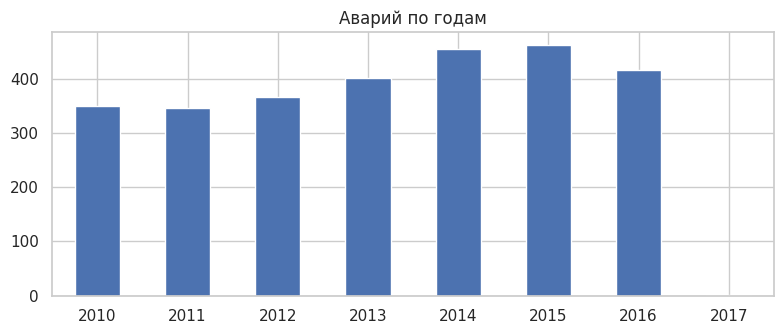

In [18]:
acc = df["Accident Date/Time"]
print(acc.min(), "—", acc.max())

months = acc.dt.to_period("M").value_counts().sort_index()
print("Месяцев:", len(months))
print(months.nsmallest(4))

acc.dt.year.value_counts().sort_index().plot.bar(figsize=(8, 3.5), rot=0)
plt.title("Аварий по годам")
plt.xlabel("")
plt.tight_layout()
plt.show()

Пустых месяцев нет, обычно бывает 30–50 аварий в месяц. Но в октябре 2010 года всего 10 записей, а в феврале 2010 — 16. Это стоит сверить с источником. 2017 год неполный (2 записи за начало января), для годовых расчетов его лучше убрать.

**Справочник операторов.**

In [19]:
names = raw.groupby("Operator ID")["Operator Name"].nunique()
print("Операторов:", raw["Operator ID"].nunique(), ", названий:", raw["Operator Name"].nunique())
print("ID с несколькими названиями:", (names > 1).sum())
raw[raw["Operator ID"].isin(names[names > 1].index)].groupby("Operator ID")["Operator Name"].unique().head()

Операторов: 213 , названий: 229
ID с несколькими названиями: 18


Operator ID
3445          [DIXIE PIPELINE, DIXIE PIPELINE COMPANY LLC]
4472     [KINDER MORGAN ENERGY PARTNERS, L.P., CYPRESS ...
11551    [LION OIL TRADING & TRANSPORTATION, INC, DELEK...
11733                                 [LOOP INC, LOOP LLC]
12628    [EXXONMOBIL PIPELINE CO, MOBIL  PIPE  LINE COM...
Name: Operator Name, dtype: object

У 18 операторов по несколько названий: переименования, слияния, двойные пробелы (`MOBIL  PIPE  LINE COMPANY`). Группировать лучше по `Operator ID`.

## 4. Проверка значений и бизнес-правил

In [20]:
num_cols = [c for c in raw.columns if "Barrels" in c or "Costs" in c] + ["Public Evacuations", "Downtime Hours"]
df[num_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Unintentional Release (Barrels),2795.0,207.245843,1368.667813,0.0,0.48,2.0,20.0,30565.0
Intentional Release (Barrels),1209.0,238.533623,2781.771453,0.0,0.0,0.0,0.0,70191.0
Liquid Recovery (Barrels),2795.0,75.051792,546.188247,0.0,0.0,0.74,8.0,18245.0
Net Loss (Barrels),2795.0,132.19405,1185.019252,0.0,0.0,0.0,2.0,30565.0
Property Damage Costs,2788.0,112296.266858,870994.744511,0.0,100.0,3000.0,25000.0,27000000.0
Lost Commodity Costs,2791.0,9805.298818,63840.749803,0.0,20.0,100.0,700.0,1417839.0
Public/Private Property Damage Costs,2785.0,25121.948654,524358.083335,0.0,0.0,0.0,0.0,23000000.0
Emergency Response Costs,2789.0,291891.133381,4617076.463688,0.0,0.0,2520.0,15500.0,177000000.0
Environmental Remediation Costs,2787.0,362809.440258,12068872.060196,0.0,0.0,800.0,15000.0,635000000.0
Other Costs,2779.0,34356.039583,619123.475831,0.0,0.0,0.0,0.0,22350000.0


Отрицательных значений нет. Среднее везде намного больше медианы (утечка: 207 баррелей в среднем против 2 по медиане). Значит, у распределений длинный правый хвост.

Pipeline Location
ONSHORE     2777
OFFSHORE      18
Name: count, dtype: int64 

Pipeline Type
ABOVEGROUND        1475
UNDERGROUND         985
TANK                301
NaN                  18
TRANSITION AREA      16
Name: count, dtype: int64 

Liquid Type
CRUDE OIL                                               1398
REFINED AND/OR PETROLEUM PRODUCT (NON-HVL), LIQUID       939
HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS               418
CO2 (CARBON DIOXIDE)                                      38
BIOFUEL / ALTERNATIVE FUEL(INCLUDING ETHANOL BLENDS)       2
Name: count, dtype: int64 



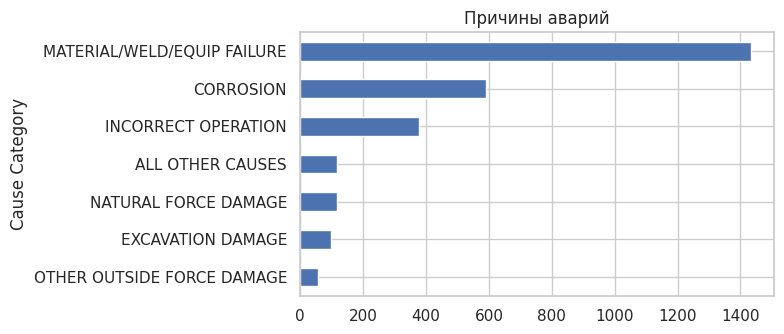

Подкатегория всегда в одной категории: True


In [21]:
for col in ["Pipeline Location", "Pipeline Type", "Liquid Type"]:
    print(raw[col].value_counts(dropna=False), "\n")

raw["Cause Category"].value_counts().sort_values().plot.barh(figsize=(8, 3.5))
plt.title("Причины аварий")
plt.tight_layout()
plt.show()

print("Подкатегория всегда в одной категории:",
      (raw.groupby("Cause Subcategory")["Cause Category"].nunique() == 1).all())

Категории чистые: опечаток и разных вариантов написания нет. Теперь проверю правила, которые должны выполняться в корректной записи. Каждое нарушение — отдельный столбец в таблице `checks`.

In [22]:
cost_parts = ["Property Damage Costs", "Lost Commodity Costs", "Public/Private Property Damage Costs",
              "Emergency Response Costs", "Environmental Remediation Costs", "Other Costs"]
shut, rest = df["Shutdown Date/Time"], df["Restart Date/Time"]
lat, lon = raw["Accident Latitude"], raw["Accident Longitude"]

# примерные границы США: материк, Аляска, Гавайи, Пуэрто-Рико
in_usa = ((lat.between(24, 49.5) & lon.between(-125, -66))
          | (lat.between(51, 72) & lon.between(-180, -129))
          | (lat.between(18, 23) & lon.between(-161, -154))
          | (lat.between(17.5, 18.6) & lon.between(-68, -65)))

checks = pd.DataFrame({
    # значения
    "All Costs != сумма затрат": (raw[cost_parts].sum(axis=1) - raw["All Costs"]).abs() > 1,
    "Net Loss != утечка - собрано": (raw["Unintentional Release (Barrels)"] - raw["Liquid Recovery (Barrels)"]
                                     - raw["Net Loss (Barrels)"]).abs() > 0.01,
    "отрицательные объемы/затраты": (raw[num_cols[:-2]] < 0).any(axis=1),
    "долгота > 0": lon > 0,
    "координаты вне США": ~in_usa,
    # согласованность полей
    "год != году из даты": acc.dt.year != raw["Accident Year"],
    "взрыв без возгорания": (raw["Liquid Explosion"] == "YES") & (raw["Liquid Ignition"] == "NO"),
    "остановка YES без даты": (raw["Pipeline Shutdown"] == "YES") & shut.isna(),
    "остановка раньше аварии": shut < acc,
    "перезапуск раньше остановки": rest < shut,
})
validity_cols = checks.columns[:5]
consistency_cols = checks.columns[5:]

checks.sum()

All Costs != сумма затрат        0
Net Loss != утечка - собрано     0
отрицательные объемы/затраты     0
долгота > 0                      3
координаты вне США               6
год != году из даты              0
взрыв без возгорания             0
остановка YES без даты           5
остановка раньше аварии         60
перезапуск раньше остановки      0
dtype: int64

Все суммы сходятся: затраты, потери в баррелях, год с датой. Взрыва без возгорания тоже нет. Проблемы три: остановка раньше аварии (60), флаг остановки без даты (5) и координаты.

In [23]:
early = checks["остановка раньше аварии"]
((acc - shut).dt.total_seconds() / 3600)[early].describe().round(1)

count     60.0
mean      11.5
std       29.5
min        0.2
25%        0.8
50%        2.0
75%        7.2
max      190.8
dtype: float64

Медиана — 2 часа. Скорее всего, время аварии — это время, когда утечку обнаружили, а трубопровод остановили раньше, по сигнализации. Удалять такие записи не нужно, но время реакции по ним считать нельзя.

Теперь координаты:

In [24]:
bad_geo = checks["долгота > 0"] | checks["координаты вне США"]
raw.loc[bad_geo, ["Operator Name", "Accident City", "Accident State", "Accident Latitude", "Accident Longitude"]]

,Operator Name,Accident City,Accident State,Accident Latitude,Accident Longitude
1502,"MAGELLAN PIPELINE COMPANY, LP",FROST,TX,32.064170,96.866140
1555,TRI-STATES NGL PIPELINE LLC,MOBILE,AL,30.390281,88.173136
1755,"EXPRESS HOLDINGS (USA), LLC",YODER,WY,41.890476,104.263399
2193,"BUCKEYE PARTNERS, LP",LINDEN,NJ,36.560830,-14.355830
2244,MARATHON PIPE LINE LLC,HITCHCOCK,TX,23.336784,-94.958220
2287,WYOMING PIPELINE COMPANY,NaN,WY,50.839319,-104.469536


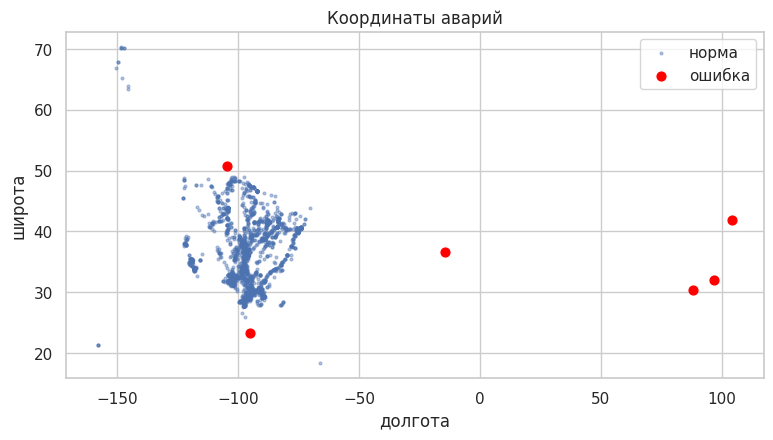

In [25]:
plt.figure(figsize=(9, 4.5))
plt.scatter(lon[~bad_geo], lat[~bad_geo], s=4, alpha=0.4, label="норма")
plt.scatter(lon[bad_geo], lat[bad_geo], s=40, color="red", label="ошибка")
plt.xlabel("долгота")
plt.ylabel("широта")
plt.legend()
plt.title("Координаты аварий")
plt.show()

У трех записей потерян минус у долготы, и точки оказались в Китае. У Линдена (Нью-Джерси) долгота -14 вместо -74, еще две точки попали в Мексику и Канаду. Знак можно исправить автоматически, остальное — вручную.

Еще проверю, нет ли одной точки, которая записана на разные штаты:

In [26]:
points = raw.groupby(["Accident Latitude", "Accident Longitude"]).agg(
    n=("Report Number", "size"),
    states=("Accident State", lambda s: ", ".join(sorted(s.dropna().unique()))),
    operator=("Operator Name", "first"),
)
points[points["states"].str.contains(",")]

,,n,states,operator
Accident Latitude,Accident Longitude,,,
38.822045,-90.078911,2,"IL, OK",EXPLORER PIPELINE CO
40.522430,-74.253840,32,"NJ, TX","KINDER MORGAN LIQUID TERMINALS, LLC"


У Kinder Morgan Liquid Terminals 32 аварии стоят в одной точке — терминал в Перт-Амбое (Нью-Джерси). Но 28 из них на самом деле в Пасадене, Техас. Видимо, оператор подставлял одни и те же координаты, так что для карт эти записи не годятся.

Текстовые поля:

In [27]:
county = raw["Accident County"].dropna()
county_clean = county.str.upper().str.replace(r"\s+(COUNTY|PARISH)$", "", regex=True).str.strip()
print("Округов:", county.nunique(), "-> после чистки:", county_clean.nunique())
print(sorted(county[county_clean == "HARRIS"].unique()))

Округов: 678 -> после чистки: 586
['HARRIS', 'HARRIS ', 'HARRIS COUNTY']


Один и тот же округ записан с суффиксом COUNTY, без него и с пробелом на конце. После простой чистки уникальных значений становится на 14% меньше.

Своевременность: первые 4 цифры `Report Number` — это год подачи отчета.

In [28]:
lag = raw["Report Number"] // 10000 - raw["Accident Year"]
lag.value_counts().sort_index()

0    2581
1     195
2      16
3       3
Name: count, dtype: int64

92% отчетов поданы в год аварии, остальные — позже, до 3 лет. Значит, последний год в данных всегда будет недосчитан.

## 5. Выбросы

Беру основные метрики и считаю выбросы двумя способами: по IQR и по z-score.

In [29]:
metrics_cols = ["Unintentional Release (Barrels)", "Net Loss (Barrels)", "All Costs", "Downtime Hours"]


def iqr_share(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean()


def z_share(s):
    s = s.dropna()
    return (((s - s.mean()) / s.std()).abs() > 3).mean()


outliers = pd.DataFrame({
    "IQR": df[metrics_cols].apply(iqr_share),
    "z-score": df[metrics_cols].apply(z_share),
}).round(3)
outliers

,IQR,z-score
Unintentional Release (Barrels),0.178,0.011
Net Loss (Barrels),0.172,0.008
All Costs,0.150,0.002
Downtime Hours,0.130,0.013


IQR находит 13–18% выбросов, z-score — около 1%. Разница из-за формы распределения: квартили почти у нуля, а несколько огромных значений раздувают стандартное отклонение. На гистограмме это хорошо видно:

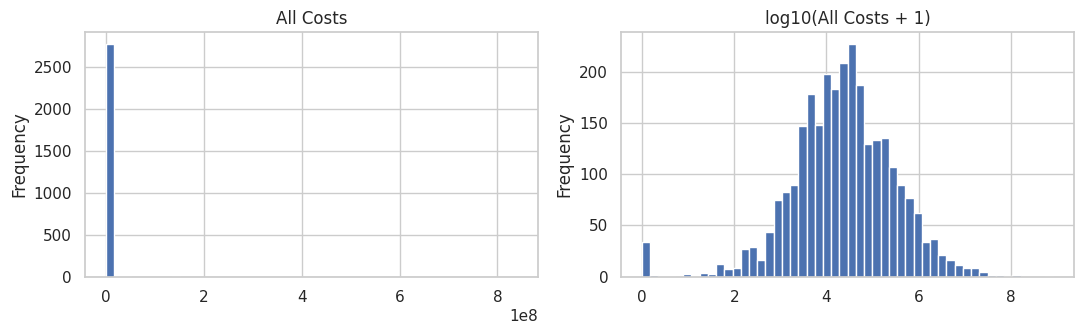

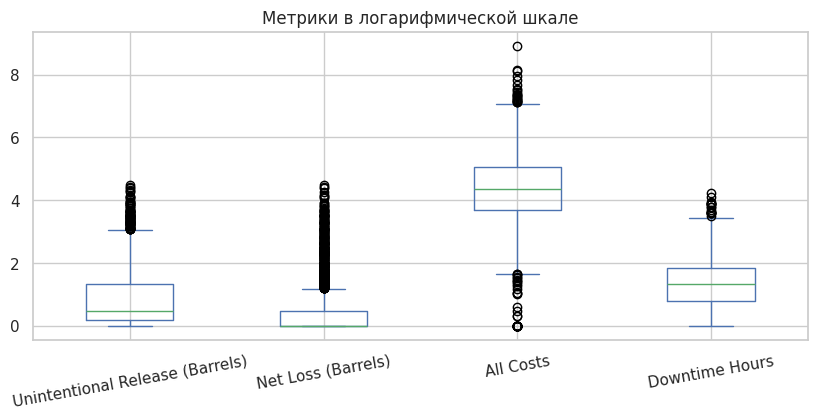

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["All Costs"].plot.hist(bins=50, ax=ax[0], title="All Costs")
np.log10(df["All Costs"] + 1).plot.hist(bins=50, ax=ax[1], title="log10(All Costs + 1)")
plt.tight_layout()
plt.show()

np.log10(df[metrics_cols] + 1).plot.box(figsize=(10, 4), rot=10, title="Метрики в логарифмической шкале")
plt.show()

In [31]:
raw.nlargest(5, "All Costs")[["Accident Date/Time", "Operator Name", "Accident City", "Accident State", "All Costs"]]

,Accident Date/Time,Operator Name,Accident City,Accident State,All Costs
194,7/25/2010 5:58 PM,"ENBRIDGE ENERGY, LIMITED PARTNERSHIP",MARSHALL,MI,840526118
2103,5/19/2015 10:57 AM,"PLAINS PIPELINE, L.P.",GOLETA,CA,142931884
523,7/1/2011 10:40 PM,EXXONMOBIL PIPELINE CO,LAUREL,MT,135000000
1173,3/29/2013 2:37 PM,MOBIL PIPE LINE COMPANY,MAYFLOWER,AR,91300000
2675,9/9/2016 11:10 AM,COLONIAL PIPELINE CO,HELENA,AL,66234072


Самые дорогие аварии реальные и известные: разлив Enbridge в Мичигане (2010), Plains у Санта-Барбары (2015), ExxonMobil на реке Йеллоустоун (2011). Удалять их нельзя, просто для таких данных лучше смотреть на медиану, а не на среднее.

In [32]:
print("Нулевые затраты:", (raw["All Costs"] == 0).sum())
print("Нулевая утечка:", (raw["Unintentional Release (Barrels)"] == 0).sum())
print("Максимальный простой, дней:", round(df["Downtime Hours"].max() / 24))

Нулевые затраты: 34
Нулевая утечка: 30
Максимальный простой, дней: 698


34 аварии с нулевыми затратами выглядят подозрительно: возможно, затраты просто не внесли. Их стоит пометить.

## 6. Корреляции

Использую корреляцию Спирмена, потому что она не так чувствительна к выбросам.

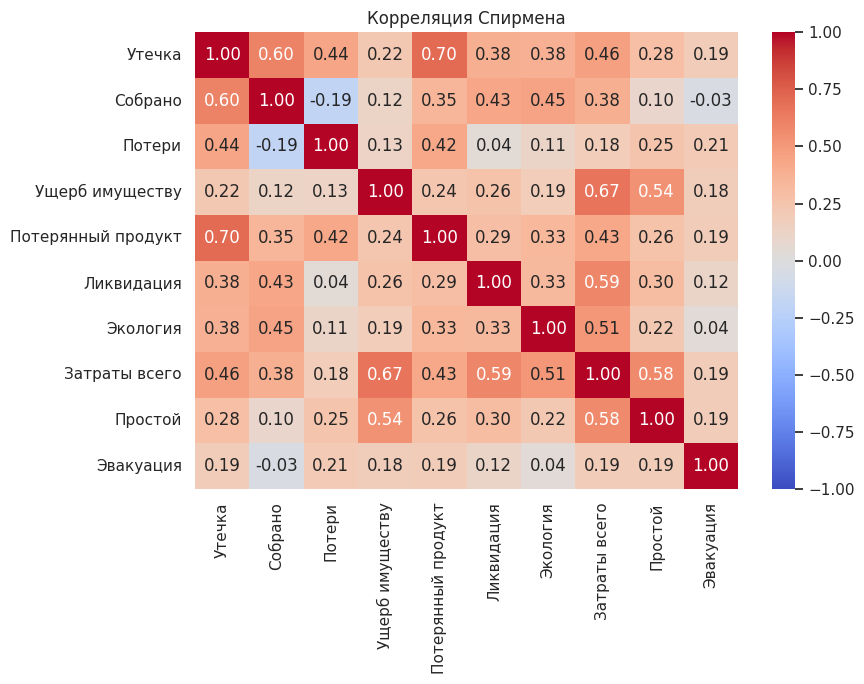

Утечка и затраты: Пирсон 0.32 , Спирмен 0.46


In [33]:
short = {
    "Unintentional Release (Barrels)": "Утечка",
    "Liquid Recovery (Barrels)": "Собрано",
    "Net Loss (Barrels)": "Потери",
    "Property Damage Costs": "Ущерб имуществу",
    "Lost Commodity Costs": "Потерянный продукт",
    "Emergency Response Costs": "Ликвидация",
    "Environmental Remediation Costs": "Экология",
    "All Costs": "Затраты всего",
    "Downtime Hours": "Простой",
    "Public Evacuations": "Эвакуация",
}
corr = df[list(short)].rename(columns=short).corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция Спирмена")
plt.tight_layout()
plt.show()

pair = df[["Unintentional Release (Barrels)", "All Costs"]]
print("Утечка и затраты: Пирсон", round(pair.corr().iloc[0, 1], 2), ", Спирмен", round(pair.corr("spearman").iloc[0, 1], 2))

Связи логичные: чем больше утечка, тем дороже потерянный продукт (0.70) и тем больше собрано (0.60). Общие затраты сильнее зависят от ущерба имуществу и ликвидации, чем от объема утечки. По Пирсону связь утечки с затратами слабее, чем по Спирмену, — снова мешают выбросы.

In [34]:
ign = pd.crosstab(raw["Liquid Type"], raw["Liquid Ignition"])
ign["доля возгораний"] = (ign["YES"] / ign.sum(axis=1)).round(3)
ign.sort_values("доля возгораний", ascending=False)

Liquid Ignition,NO,YES,доля возгораний
Liquid Type,,,
"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",379,39,0.093
CRUDE OIL,1365,33,0.024
"REFINED AND/OR PETROLEUM PRODUCT (NON-HVL), LIQUID",916,23,0.024
BIOFUEL / ALTERNATIVE FUEL(INCLUDING ETHANOL BLENDS),2,0,0.000
CO2 (CARBON DIOXIDE),38,0,0.000


Сжиженные газы (HVL) загораются в 9% случаев, нефть — в 2%, CO₂ не горит. Это согласуется с физикой, значит флаги заполнены правдоподобно.

## 7. Метрики качества

In [35]:
not_applicable = victim_cols + ["Liquid Subtype", "Liquid Name"]

quality = pd.DataFrame([
    ["Completeness", 1 - raw.isna().mean().mean(), "≥ 0.98"],
    ["Completeness без неприменимых полей", 1 - raw.drop(columns=not_applicable).isna().mean().mean(), "≥ 0.98"],
    ["Uniqueness", raw["Report Number"].nunique() / len(raw), "= 1.0"],
    ["Validity", 1 - checks[validity_cols].any(axis=1).mean(), "≥ 0.99"],
    ["Consistency", 1 - checks[consistency_cols].any(axis=1).mean(), "≥ 0.98"],
    ["Timeliness (отчет в год аварии)", (lag == 0).mean(), "-"],
    ["Duplication Rate", raw.duplicated().mean(), "≤ 0.01"],
    ["Outlier Ratio (IQR)", outliers["IQR"].mean(), "≤ 0.02"],
], columns=["метрика", "значение", "норма"])
quality["значение"] = quality["значение"].round(3)
quality

,метрика,значение,норма
0,Completeness,0.678,≥ 0.98
1,Completeness без неприменимых полей,0.940,≥ 0.98
2,Uniqueness,1.000,= 1.0
3,Validity,0.998,≥ 0.99
4,Consistency,0.977,≥ 0.98
5,Timeliness (отчет в год аварии),0.923,-
6,Duplication Rate,0.000,≤ 0.01
7,Outlier Ratio (IQR),0.158,≤ 0.02


## 8. Выводы

Данные в целом аккуратные: ключи уникальны, дубликатов нет, категории чистые, суммы сходятся. Не дотягивают до нормы полнота (0.68, без неприменимых полей — 0.94), согласованность (0.977) и доля выбросов (0.16). Но выбросы здесь — реальные крупные аварии, а не ошибки.

Что сделать в ETL:
- даты парсить с отдельным форматом для каждого столбца, флаги переводить в nullable `boolean`, счетчики людей — в `Int64`;
- пропуски в полях о пострадавших заменить на 0, неприменимые поля (подтип нефти, тип морского трубопровода) пометить как N/A;
- учитывать, что часть полей заполняется только с определенного года, и не сравнивать их между периодами;
- убрать или пометить неполный 2017 год, проверить октябрь 2010 и возможный дубль 20150132/20150133;
- исправить знак долготы, пометить координаты вне США и «шаблонные» координаты Kinder Morgan;
- вынести операторов в отдельный справочник по `Operator ID`, почистить названия округов;
- выбросы не удалять, в отчетах использовать медиану;
- проверки из раздела 4 автоматизировать, например через Pandera, чтобы ловить ошибки источника на входе.